In [1]:
##############
## INITIATE ##
##############

## Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

## Import modules
from f_wsi_reader import slide_path_to_tiles_at_coordinates
from f_wsi_reader import get_tile_map
from f_wsi_reader import get_tile_map_fast
from f_wsi_reader import read_slide
from f_wsi_reader import get_dimensions
from f_wsi_reader import apply_all_filters
from f_wsi_reader import apply_all_transforms
from f_wsi_reader import reassemble_tiles
from f_wsi_reader import select_patches_on_grid
from f_wsi_reader import get_tissue_mask
from f_extract_objects import extract_object_pixels
from f_extract_objects import polish
from f_extract_objects import inlay_objects
from f_extract_objects import get_bounding_box_square
# from f_model import UNet as Model
from f_model_transformer import UNetTransformer as Model

#
###

In [26]:
###########
## PATHS ##
###########

## Paths
wsi_paths = ['/Volumes/Elements/BDI/datasets/ICGCC/images/svs/TB10.0230_V10_03.svs'] # '/Users/user/Documents/projects/GlandSeg/data/examples/0a93d9a674e358ba32e4e2ec320aefc5.tiff'

## Path to output
PT_OUTPUT_FOLDER = f'/Users/zool1262/Desktop/tmp/' # Path where the gland images should be saved

#
###

In [5]:
##########################
## GET TILE COORDINATES ##
##########################

## Parameters
TILE_SIZE = 64 # Size of tiles for tissue extraction
FILTER_LOW = 10 # Low filter to remove black tiles
FILTER_HIGH = 240 # High filter to remove white tiles
FILTER_STD = 2 # Std filter to remove grey tiles
WSI_PATH = wsi_paths[0] # Path to WSI

## Open slide
slide = read_slide(WSI_PATH)
slide_size = get_dimensions(slide)

## Get tile_map
thumbnail, tile_map, canvas_size = get_tile_map(slide, TILE_SIZE)

## Get tissue mask
mask = get_tissue_mask(tile_map, FILTER_LOW, FILTER_STD, FILTER_HIGH)

## Get coordinates of tiles with tissue
tile_coordinates = (np.argwhere(mask[:,:,0] > 0) * TILE_SIZE).astype(int)
tile_coordinates = [[tile_coordinate[0], tile_coordinate[1]] for tile_coordinate in tile_coordinates] # (x: H, y: W)

## Compute slide-level tissue mask
tissue_mask = cv2.resize(mask, (canvas_size[1], canvas_size[0]), cv2.INTER_LINEAR)[:,:,None] # (H, W)

#
###

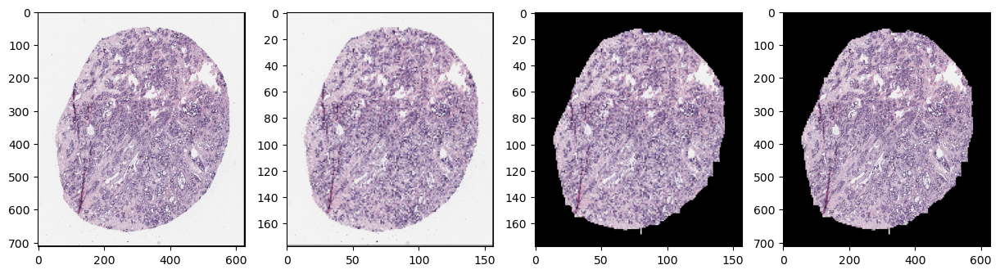

In [6]:
###################################
## GET TILE COORDINATES - CHECKS ##
###################################

## Compute pixel-tile tissue mask (For checks)
tile_map_masked = tile_map * mask
thumbnail_masked = thumbnail * cv2.resize(mask, (thumbnail.shape[1], thumbnail.shape[0]), cv2.INTER_LINEAR)[:,:,None] # (H, W)

## Visualise mask
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
axes[0].imshow(thumbnail)
axes[1].imshow(tile_map)
axes[2].imshow(tile_map_masked)
axes[3].imshow(thumbnail_masked)
plt.show()
plt.close()

#
###

In [7]:
###############################
## EXTRACT PATCHES FOR MODEL ##
###############################

## Parameters
LEVEL = 0 # Downsampling level 
TILE_SIZE_MODEL = 1024 # Size of tile for model

## Remove patches too close to the edges
tile_coordinates_thinned = []
for tile_coordinates_ in tile_coordinates:
    coords_0_lo = tile_coordinates_[0] + int(TILE_SIZE/2) - int(TILE_SIZE_MODEL/2)
    coords_0_hi = tile_coordinates_[0] + int(TILE_SIZE/2) + int(TILE_SIZE_MODEL/2)
    coords_1_lo = tile_coordinates_[1] + int(TILE_SIZE/2) - int(TILE_SIZE_MODEL/2)
    coords_1_hi = tile_coordinates_[1] + int(TILE_SIZE/2) + int(TILE_SIZE_MODEL/2)
    if (coords_0_lo > 0) & (coords_0_hi < canvas_size[0]) & (coords_1_lo > 0) & (coords_1_hi < canvas_size[1]):
        tile_coordinates_thinned += [[coords_0_lo, coords_1_lo]]

## Get patches closest to grid points
tile_coordinates_thinned = select_patches_on_grid(tile_coordinates_thinned, grid_spacing=512)

## Load patches from the dataset
patches = slide_path_to_tiles_at_coordinates(WSI_PATH, tile_coordinates_thinned, TILE_SIZE_MODEL, LEVEL) # [dataset[i] for i in range(min(num_patches_to_display, len(dataset)))]
print(f'Number of patches: {len(tile_coordinates_thinned)}')

#
###

Number of patches: 313


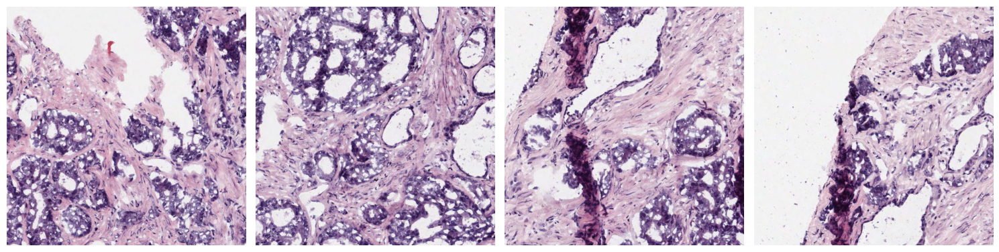

In [46]:
########################################
## EXTRACT PATCHES FOR MODEL - CHECKS ##
########################################

## Display the patches
num_patches_to_display = 4
fig, axes = plt.subplots(1, num_patches_to_display, figsize=(15, 5))
for i, ax in enumerate(axes.flat):
    if i < len(patches):
        ax.imshow(patches[i])
        ax.axis('off')
    else:
        ax.axis('off') # Hide unused subplots if any
plt.tight_layout()
plt.show()

#
###

In [9]:
####################
## REASSEMBLE WSI ##
####################

## Reassemble image
img = reassemble_tiles(patches, tile_coordinates_thinned, canvas_size[0], canvas_size[1])

## Mask
img = img * tissue_mask

#
###

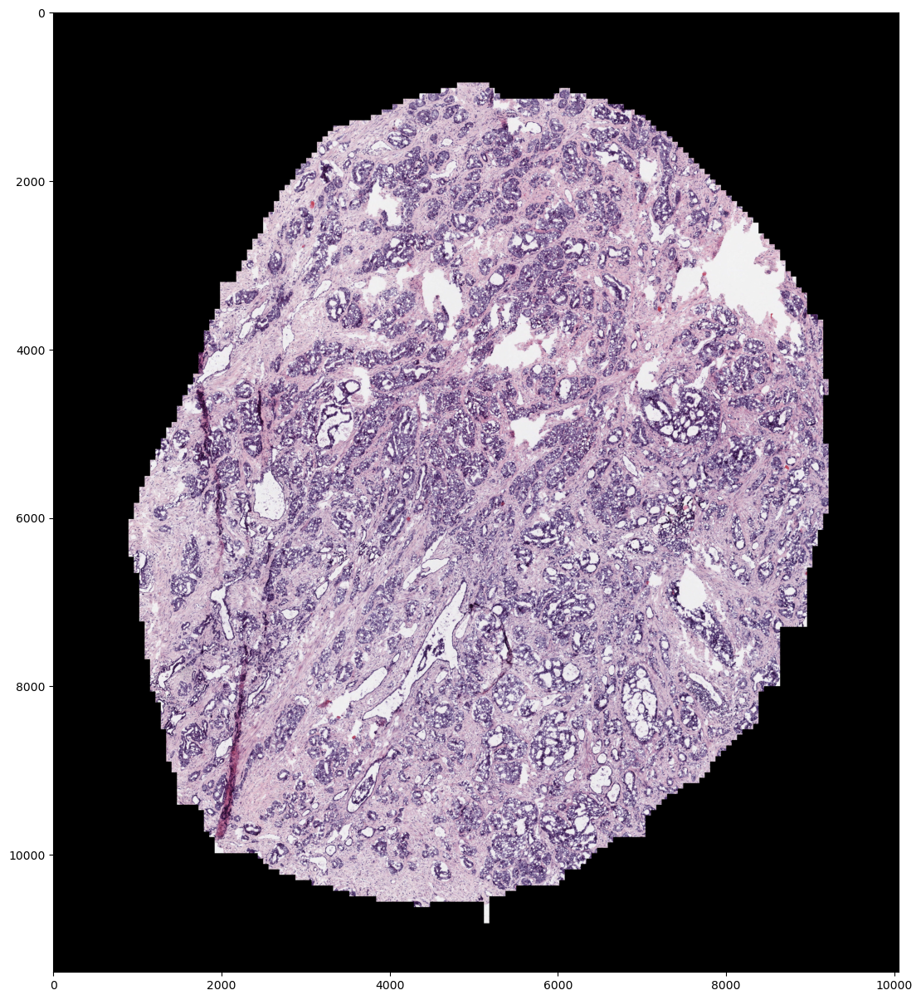

In [10]:
#############################
## REASSEMBLE WSI - CHECKS ##
#############################

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15, 15))
axes.imshow(img)
plt.show()
plt.close()

#
###

In [11]:
#####################################
## FUNCTIONS FOR MODEL APPLICATION ##
#####################################

## numpy_to_device
## Goal:
## Format numpy array for model.
## Inputs:
## X (list of numpy arrays): Input array for the model (B, H, W, C).
## Outputs:
## tensors (list of torch tensors): Output tensor for model (B, C, H, W).
def numpy_to_device(X, tile_size, device):
    tensors = []
    for x in X:        
        x = cv2.resize(x, (tile_size, tile_size))
        x = torch.tensor(x)        
        x = x.swapaxes(2, 1).swapaxes(1, 0) # (H, W, C) --> (C, H, W)
        x = x.float()
        x = x[None, :, :, :] # (C, H, W) --> (B=1, C, H, W)
        x = x.to(device)
        tensors += [x]        
    return tensors

## device_to_numpy
## Goal: 
## Format tensor on device back to numpy array.
## Inputs:
## X (list of torch tensors): List of torch tensors predictions from the model (B, C, H, W).
## Outputs:
## images (list of numpy arrays): List of images produced by the model after re-formatting (B, H, W, C).
def device_to_numpy(X, tile_size):
    images = []
    for x in X:
        x = torch.sigmoid(x) * 255 # Logits to probabilities to [0, 255]
        x = x.cpu().numpy()
        x = x.swapaxes(0, 1).swapaxes(1, 2)    
        x = x.astype('uint8')
        x = cv2.resize(x, (tile_size, tile_size))
        x = np.argmax(x, axis=2).reshape(x.shape[0], x.shape[1], 1) # Only for multiple classes
        images += [x]        
    return images

#
###

In [10]:
"""
################
## LOAD MODEL ##
################

## Parameters
DEVICE = "mps" # Device to load model, tiles, and perform computations
# PT_MODEL_IN = 'models/r10_3.pth'
# NUM_CLASSES = 4 # Number of outputs given by model
PT_MODEL_IN = 'models/TransUNet_V1_1.pth' # Path to model weights
NUM_CLASSES = 3 # Number of outputs given by model

## Load model
print(f"Using {DEVICE} device")
model = Model(n_classes=NUM_CLASSES).to(DEVICE)
if os.path.exists(PT_MODEL_IN):
    model.load_state_dict(torch.load(PT_MODEL_IN))
    print("Loaded model")

#
###
"""

Using mps device
Loaded model


/var/folders/mf/6vvt1nwx5zz1gr1nj3hnqfzr0000gp/T/ipykernel_3400/3937862740.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(PT_MODEL_IN)

In [14]:
#####################
## LOAD MODEL DUAL ##
#####################

## Model classes
from f_model import UNet
from f_model_transformer import UNetTransformer

DEVICE = "mps" # Device to load model, tiles, and perform computations

## Load model
device = DEVICE
print(f"Using {device} device")
pt_model_in = 'models/UNet_V1_1.pth'
model_1 = UNet(n_classes=3).to(device)
if os.path.exists(pt_model_in):
    model_1.load_state_dict(torch.load(pt_model_in))
    print("Loaded model")

## Load model
device = "mps"
print(f"Using {device} device")
pt_model_in = 'models/TransUNet_V1_1.pth'
model_2 = UNetTransformer(n_classes=3).to(device)
if os.path.exists(pt_model_in):
    model_2.load_state_dict(torch.load(pt_model_in))
    print("Loaded model")

## Combine models
def model(X):
    return model_1(X) + model_2(X)

#
###

Using mps device
Loaded model
Using mps device
Loaded model


/var/folders/tb/4hh90ttd1nl4xf1zbfyq_n8w0000gp/T/ipykernel_89592/3209255181.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_1.load_state_dict(torch.load(pt_model_

In [15]:
#################
## APPLY MODEL ##
#################

## Apply to all tiles
preds = []
X = numpy_to_device(patches, TILE_SIZE_MODEL, DEVICE)
with torch.no_grad():
    for x in X:                
        preds_ = model(x) # (B, C, H, W)
        preds_ = device_to_numpy(preds_, TILE_SIZE_MODEL)[0] # WiP: Only for single patch
        preds += [preds_] # WiP: Only for single patch

#
###

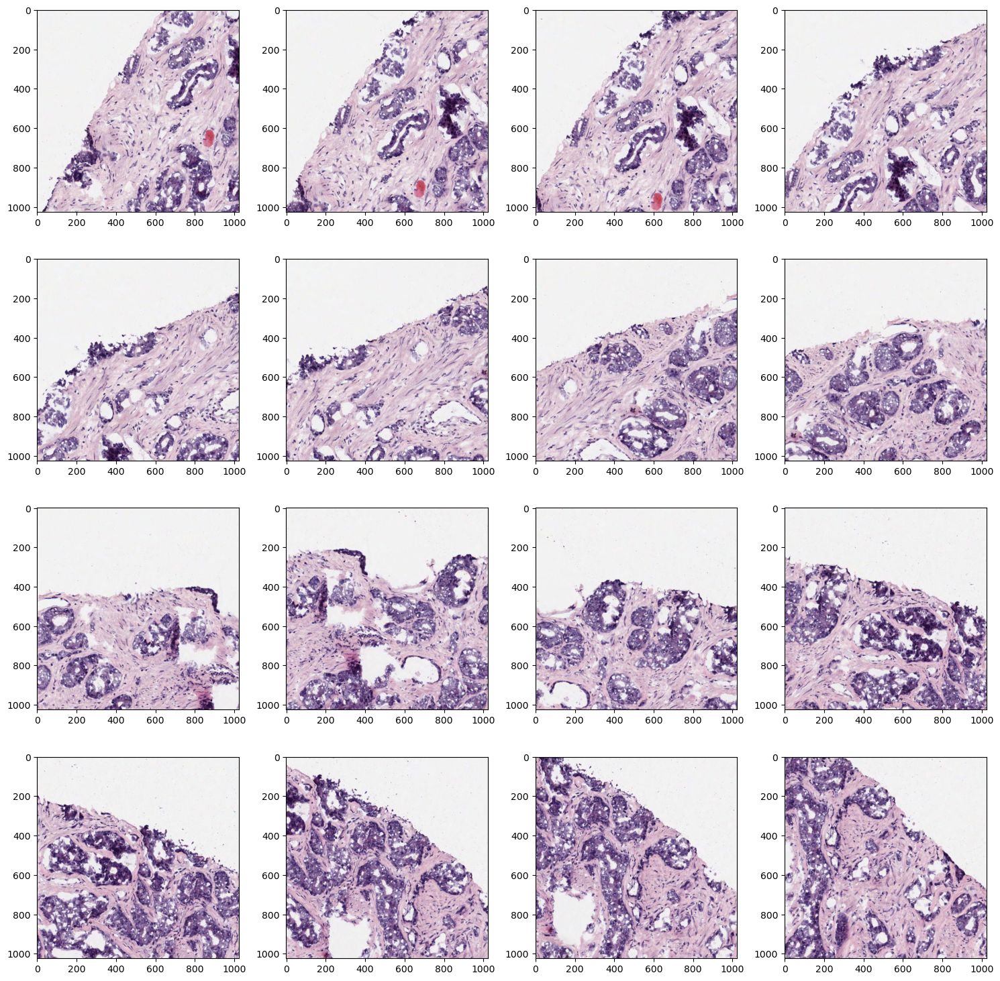

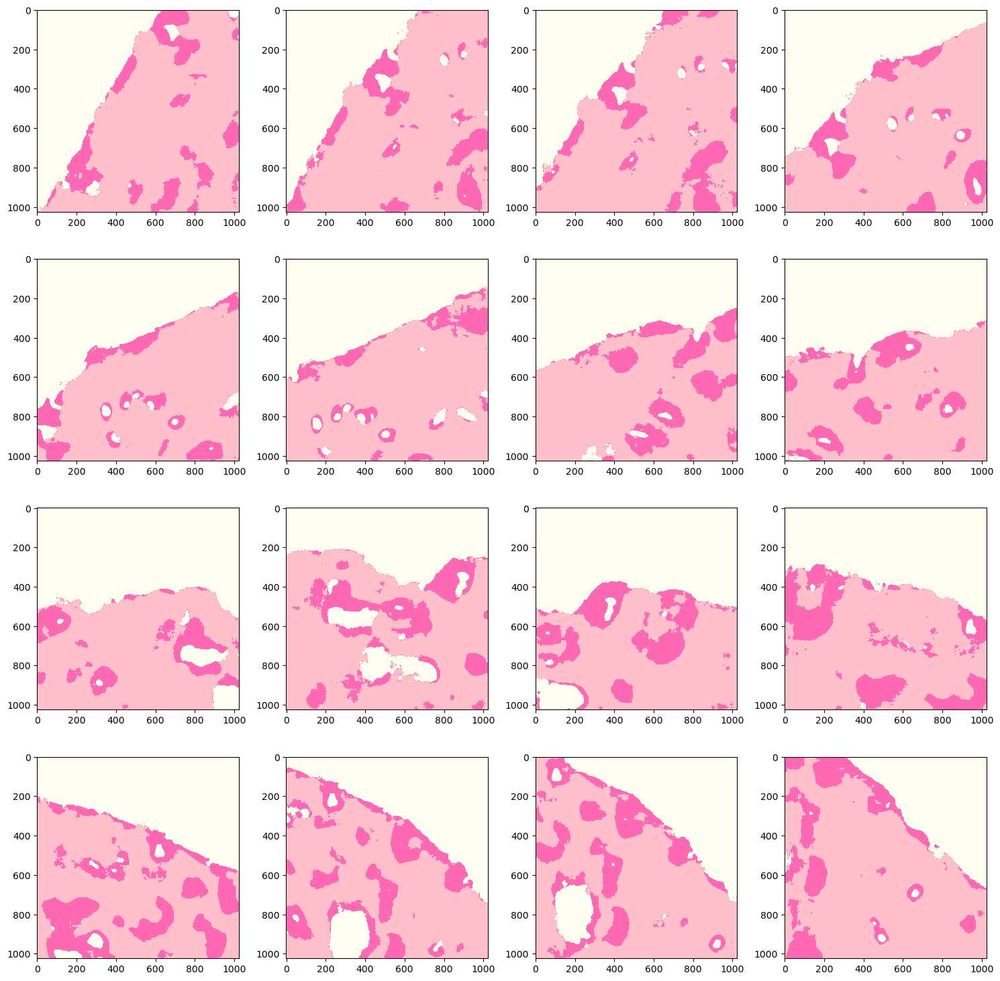

In [16]:
##########################
## APPLY MODEL - CHECKS ##
##########################

## Parameters
theme = 'H&E'

## Graphical parameters
if theme == 'H&E':
    from matplotlib.colors import ListedColormap
    custom_cmap = ListedColormap(['pink', 'hotpink', 'ivory'])
else:
    custom_cmap = 'gist_gray'

## Visualise image patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]        
        axis.imshow(patches[k], cmap=custom_cmap)
        k += 1
plt.tight_layout()
plt.show()
plt.close()

## Visualise prediction patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]
        axis.imshow(preds[k], cmap=custom_cmap)        
        k += 1
plt.tight_layout()
plt.show()
plt.close()

#
###

In [17]:
############################
## REASSEMBLE PREDICTIONS ##
############################

## Assemble predictions
mask = reassemble_tiles(preds, tile_coordinates_thinned, canvas_size[0], canvas_size[1])
mask = mask[:,:,0].reshape(mask.shape[0], mask.shape[1], 1) * tissue_mask

## Keep full size mask
mask_full_size = mask

#
###

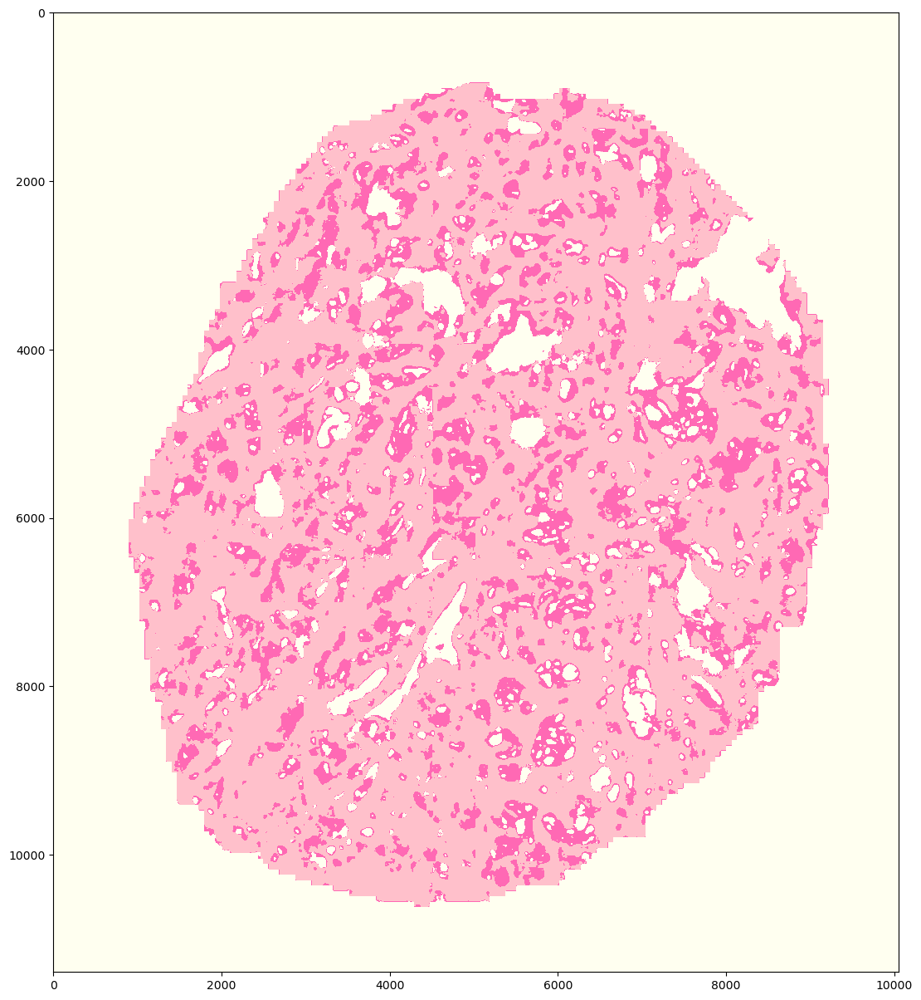

In [18]:
#####################################
## REASSEMBLE PREDICTIONS - CHECKS ##
#####################################

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15, 15))
if theme == 'H&E':
    axes.imshow(mask + (1 - tissue_mask) * 2, cmap=custom_cmap)
else:
    axes.imshow(mask, cmap=custom_cmap)
plt.show()
plt.close()

#
###

In [19]:
########################################
## PREPARE MASK FOR OBJECT EXTRACTION ##
########################################

## Parameters
DOWNSAMPLE_EXTRACTION = 4 # Downsample factor of mask for extraction of objects
NUM_POLISH = 1 # Number of times to erode mask (reduced clumped objects but may lose small objects)

## Binarise mask
mask = ((mask > 0)*1).astype('uint8')
mask = cv2.resize(mask, (int(mask.shape[1]/DOWNSAMPLE_EXTRACTION), int(mask.shape[0]/DOWNSAMPLE_EXTRACTION)))
mask = mask[:,:,None]

## Polish mask
for i in range(NUM_POLISH):
    mask = polish(mask)
    mask = mask[:,:,None]

## Downscale tissue mask
tissue_mask_downsampled = cv2.resize(tissue_mask, (int(tissue_mask.shape[1]/DOWNSAMPLE_EXTRACTION), int(tissue_mask.shape[0]/DOWNSAMPLE_EXTRACTION)))
tissue_mask_downsampled = tissue_mask_downsampled[:,:,None]

#
###

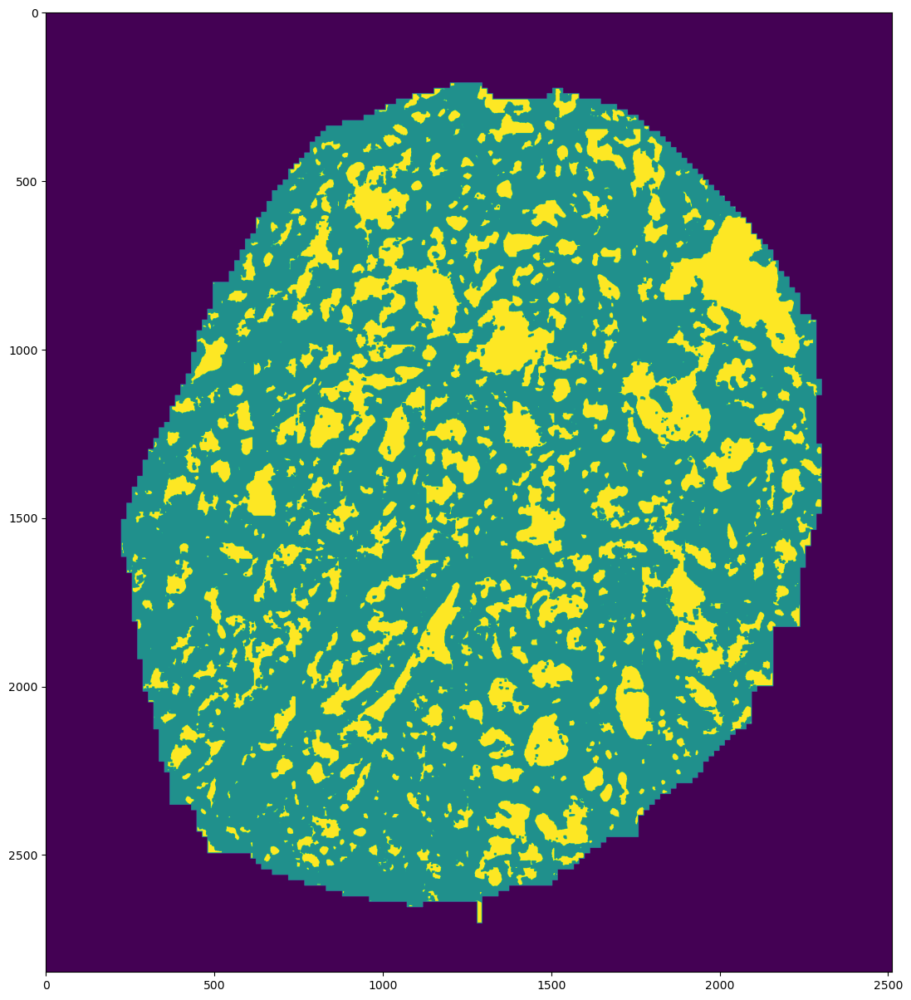

In [20]:
#################################################
## PREPARE MASK FOR OBJECT EXTRACTION - CHECKS ##
#################################################

## Visualise
fig, axes = plt.subplots(1, 1, figsize=(15,15))
axes.imshow(mask + tissue_mask_downsampled)
plt.show()
plt.close()

#
###

In [21]:
#####################
## EXTRACT OBJECTS ##
#####################

## Get objects
gland_coords = extract_object_pixels(mask)
print(f'Number of glands: {len(gland_coords)}')

#
###

Number of glands: 984


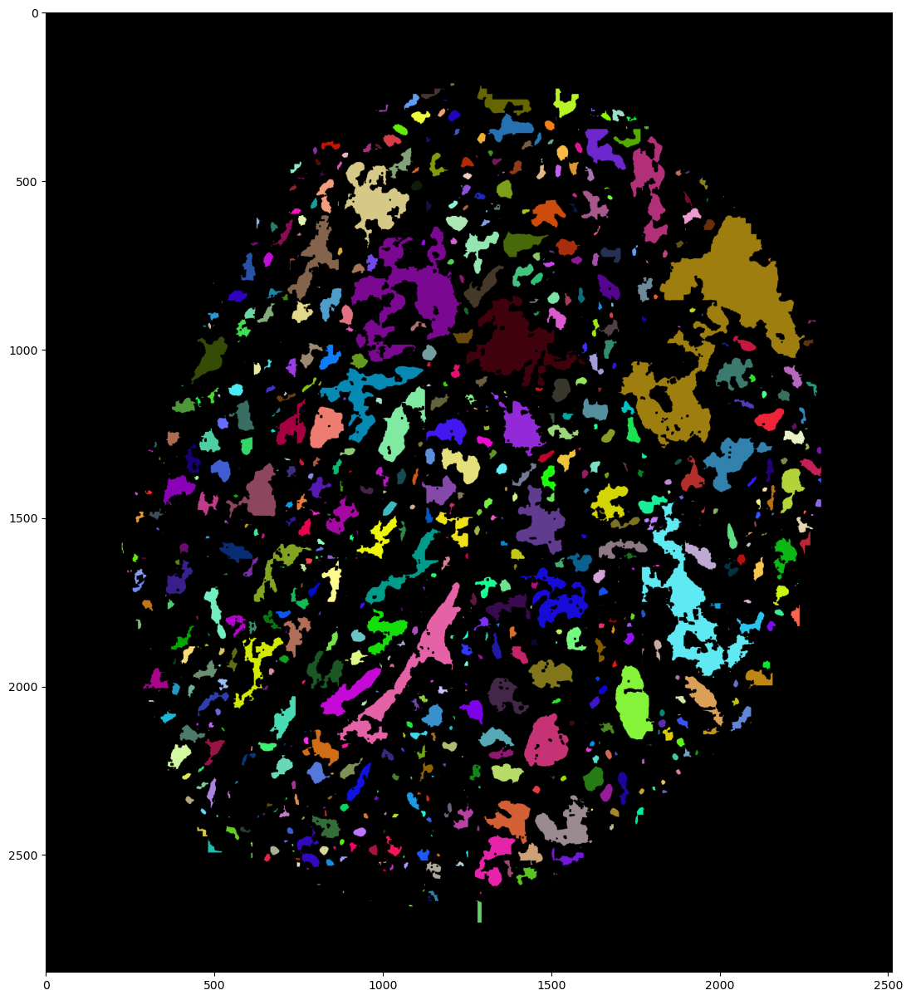

In [22]:
##############################
## EXTRACT OBJECTS - CHECKS ##
##############################

## Visualise objects
fig, axes = plt.subplots(1, 1, figsize=(15,15))
axes.imshow(inlay_objects(mask, gland_coords))
plt.show()
plt.close()

#
###

In [23]:
####################
## FILTER OBJECTS ##
####################

## Parameters
BUFFER = 64 # Added distance around bounding box (in pixels)
THRESHOLD_MIN = 1000 # Minimum surface area of objects (in pixels)
THRESHOLD_MAX = 4000000 # Maximum surface area of objects (in pixels)
PROP_BLACK = 0.0 # Maximum proportion of border pixels in image (proportion)

## Criteria for filtering
buffer = BUFFER // DOWNSAMPLE_EXTRACTION # Added distance around bounding box (in pixels)
threshold_min = THRESHOLD_MIN // (DOWNSAMPLE_EXTRACTION ** 2) # Minimum surface area of objects (in pixels)
threshold_max = THRESHOLD_MAX // (DOWNSAMPLE_EXTRACTION ** 2) # Maximum surface area of objects (in pixels)

## Extract and save each object
gland_coords_thinned = []
for i, coords in enumerate(gland_coords):

    ## Discard small objects
    if (len(coords) > threshold_min) & (len(coords) < threshold_max):
        
        ## Get bounding box of the object
        x_min, y_min, x_max, y_max = get_bounding_box_square(gland_coords[i])

        ## Get object
        object_img = mask[(x_min - buffer):(x_max + buffer), (y_min - buffer):(y_max + buffer)]
        object_tissue = tissue_mask_downsampled[(x_min - buffer):(x_max + buffer), (y_min - buffer):(y_max + buffer)]
        
        ## Check size
        if (object_img.shape[0] > 0) & (object_img.shape[1] > 0):
            
            if object_tissue.sum()/(object_tissue.shape[0] * object_tissue.shape[1]) >= (1 - PROP_BLACK):                    
        
                ## Save the object coordinates
                gland_coords_thinned += [gland_coords[i]]

## Check final number of glands
print(f'Final number of glands: {len(gland_coords_thinned)}')

## Rescale coordinates to original size
rescaled_gland_coords = [coords * DOWNSAMPLE_EXTRACTION for coords in gland_coords_thinned]

#
###

Final number of glands: 500


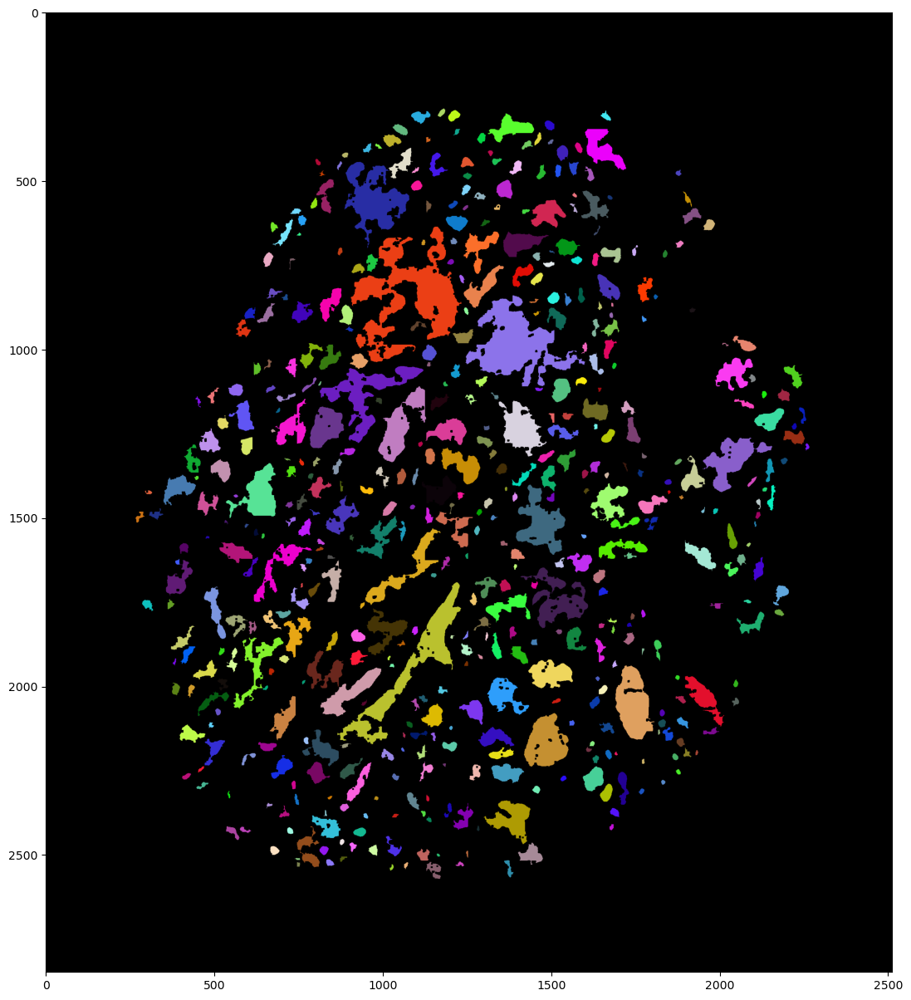

In [24]:
##############################
## EXTRACT OBJECTS - CHECKS ##
##############################

## Visualise objects
fig, axes = plt.subplots(1, 1, figsize=(15,15))
axes.imshow(inlay_objects(mask, gland_coords_thinned))
plt.show()
plt.close()

#
###

In [27]:
##################
## SAVE OBJECTS ##
##################

## Paths
os.makedirs(PT_OUTPUT_FOLDER, exist_ok=True)

## Extract and save each object
img_objects = []
mask_objects = []
for i, coords in enumerate(rescaled_gland_coords):
        
    ## Get bounding box of the object
    x_min, y_min, x_max, y_max = get_bounding_box_square(coords)
    
    ## Get object
    object_img = img[(x_min - BUFFER):(x_max + BUFFER), (y_min - BUFFER):(y_max + BUFFER)]
    object_img = cv2.cvtColor(object_img, cv2.COLOR_BGR2RGB)
    
    ## Get mask
    object_mask = mask_full_size[(x_min - BUFFER):(x_max + BUFFER), (y_min - BUFFER):(y_max + BUFFER)]    
    object_mask = cv2.cvtColor(object_mask, cv2.COLOR_BGR2RGB)
    object_mask[:,:,0] = ((object_mask[:,:,0] == 0) * 255).astype(np.uint8)
    object_mask[:,:,1] = ((object_mask[:,:,1] == 1) * 255).astype(np.uint8)
    object_mask[:,:,2] = ((object_mask[:,:,2] == 2) * 255).astype(np.uint8)
        
    ## Save the object image
    img_objects += [object_img]
    object_filename = os.path.join(PT_OUTPUT_FOLDER, f'{os.path.basename(WSI_PATH)}__{x_min}_{x_max}_{y_min}_{y_max}.png')
    cv2.imwrite(object_filename, object_img)    

    ## Save the mask image
    mask_objects += [object_mask]
    object_filename = os.path.join(PT_OUTPUT_FOLDER, f'{os.path.basename(WSI_PATH)}__{x_min}_{x_max}_{y_min}_{y_max}_mask.png')
    cv2.imwrite(object_filename, object_mask)

#
###

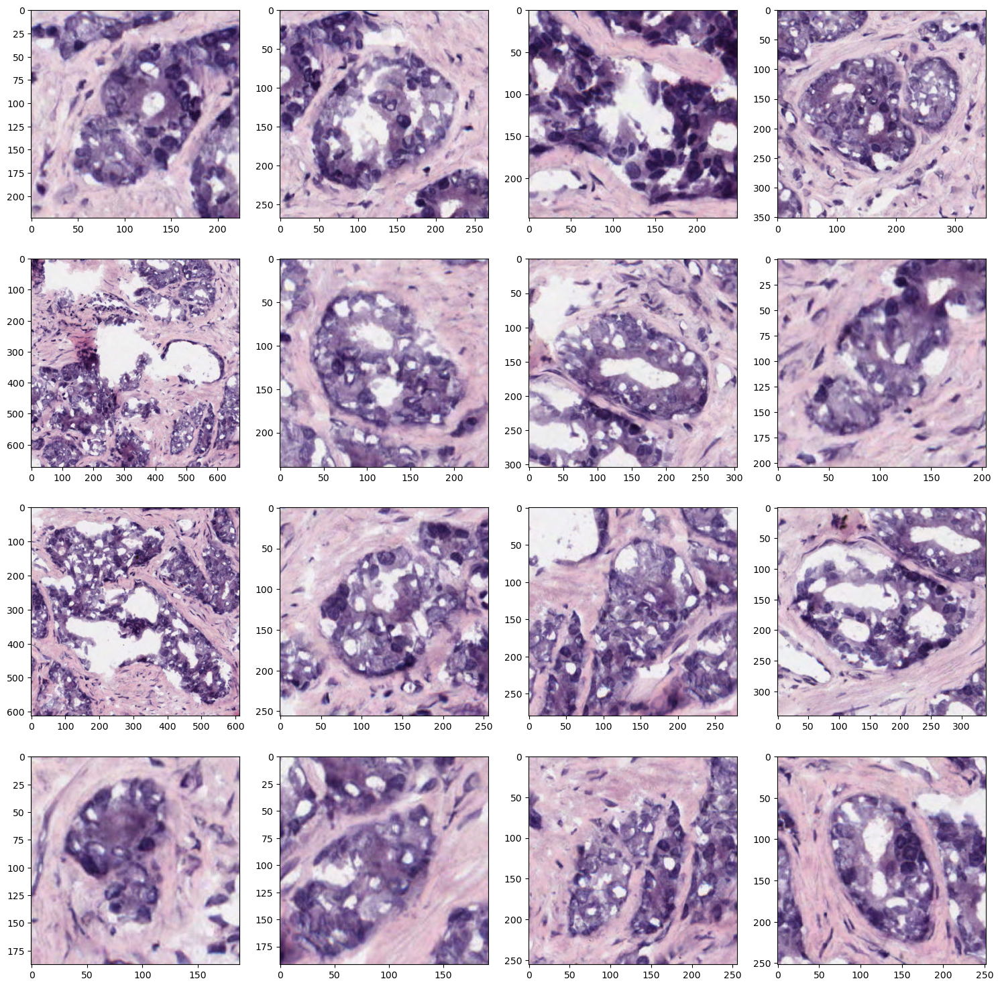

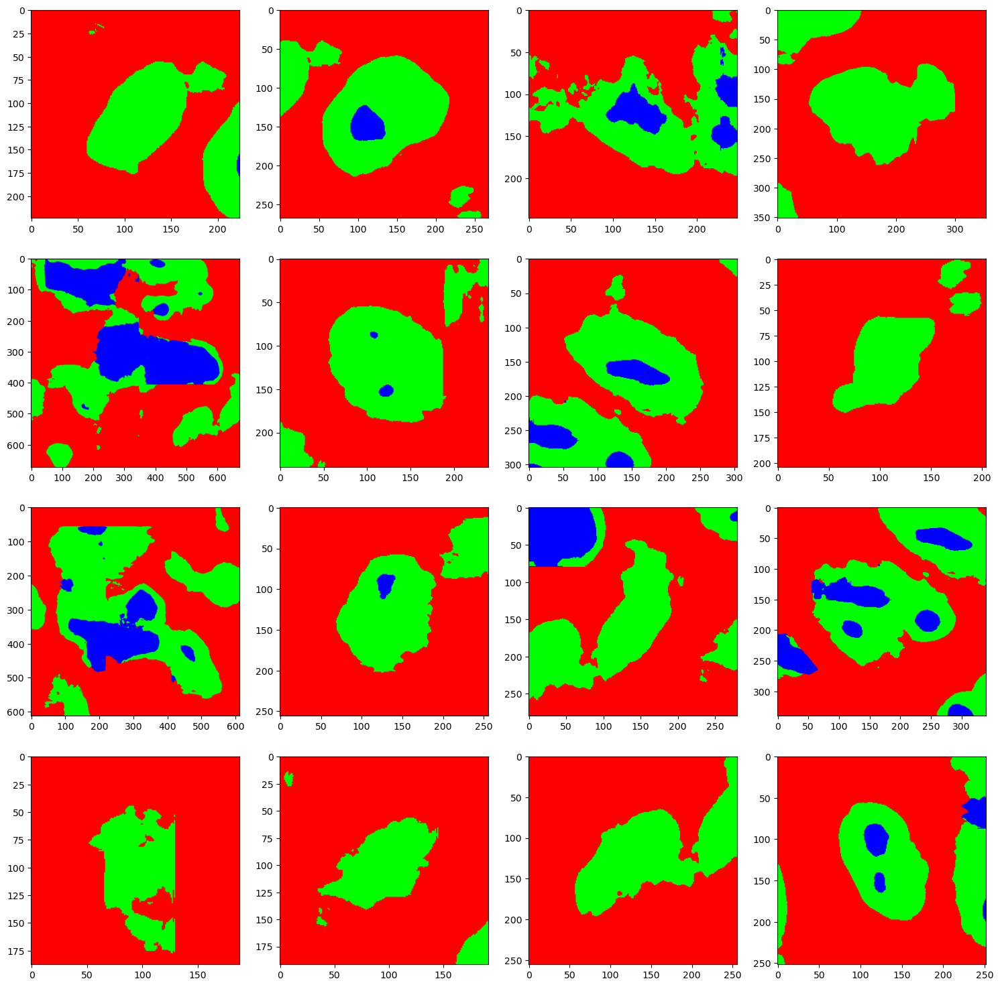

In [28]:
###########################
## SAVE OBJECTS - CHECKS ##
###########################

## Visualise image patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]        
        axis.imshow(cv2.cvtColor(img_objects[k], cv2.COLOR_BGR2RGB))
        k += 1
plt.tight_layout()
plt.show()
plt.close()

## Visualise image patches
fig, axes = plt.subplots(4, 4, figsize=(15,15))
k = 0
for i in range(4):
    for j in range(4):
        axis = axes[i,j]        
        axis.imshow(mask_objects[k])
        k += 1
plt.tight_layout()
plt.show()
plt.close()

#
###